# In-class work 1. First look at industrial data

Industrial AI, KBTU. Goes with Lecture 1.

Not graded. We set up the tools, load a real data set and go through the basics: what a table
of sensor data looks like, what a population and a sample are, how to read a histogram and a
boxplot, and what noise does to all of it.

You need no data science for this. If you have never used pandas, start at section 1 and type
along with us.

There is nothing to download by hand. The notebook fetches its data set from Kaggle itself, so
it runs the same way on your laptop and in Google Colab.

Run the cells one by one with `Shift+Enter`. Where you see **Question**, answer it in your head
before you run the next cell.

In [2]:
import warnings
warnings.filterwarnings("ignore")

import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

BLUE, ORANGE, RED, GREEN, PURPLE, GREY = (
    "#2a6f8e", "#e07b39", "#c0392b", "#4a8f5a", "#9b3f9b", "#9aa0a6")

mpl.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#cccccc",
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e6e6",
    "grid.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.labelsize": 10,
    "font.size": 10,
    "font.family": ["Segoe UI", "DejaVu Sans", "sans-serif"],
    "legend.frameon": False,
    "lines.linewidth": 1.6,
})

pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

KAGGLE = {
    'ai4i': 'stephanmatzka/predictive-maintenance-dataset-ai4i-2020',
}


def dataset_folder(name):
    """The folder with the files of a data set: the Kaggle copy (downloaded once, then cached),
    or data/<name>/ of the course repo if Kaggle is out of reach."""
    if KAGGLE[name]:
        try:
            import contextlib, io, logging, kagglehub
            logging.getLogger("kagglehub").setLevel(logging.ERROR)
            with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
                folder = Path(kagglehub.dataset_download(KAGGLE[name]))
            print(f"{name}: Kaggle {KAGGLE[name]}")
            return folder
        except Exception as exc:
            print(f"Kaggle unavailable ({type(exc).__name__}), looking for data/{name}/")
    for root in [Path.cwd(), *Path.cwd().parents]:
        if (root / "data" / name).is_dir():
            return root / "data" / name
    raise FileNotFoundError(f"no data/{name}/ here or above; run data/fetch.py in the course repo")

print(" | ".join(f"{m} {sys.modules[m].__version__}" for m in
                 ("numpy", "pandas", "matplotlib", "scipy", "sklearn", "torch") if m in sys.modules))

numpy 2.5.5 | pandas 3.1.1 | matplotlib 3.11.2 | torch 2.8.0+cu128


The first cell imports the libraries, sets the look of the plots and defines
`dataset_folder`, which we use in section 2. It ends by printing the library versions. If an
import fails, install the missing package and restart the kernel:

```
pip install numpy pandas matplotlib kagglehub torch
```

## 1. NumPy

NumPy stores numbers in an **array**: a row or a table of numbers of one type. Arithmetic on an
array applies to every element at once, so you almost never write a loop.

In [3]:
a = np.array([3.1, 2.0, 5.4, 4.8, 3.9])

print("array ", a)
print("length", len(a))
print("type  ", a.dtype)

array  [3.1 2.  5.4 4.8 3.9]
length 5
type   float64


In [4]:
print("a + 10", a + 10)      # applied to every element
print("a * 2 ", a * 2)
print("a ** 2", a ** 2)

a + 10 [13.1 12.  15.4 14.8 13.9]
a * 2  [ 6.2  4.  10.8  9.6  7.8]
a ** 2 [ 9.61  4.   29.16 23.04 15.21]


The usual statistics are methods of the array.

In [5]:
print("sum    ", a.sum())
print("mean   ", a.mean())
print("min max", a.min(), a.max())
print("std    ", a.std())

sum     19.2
mean    3.84
min max 2.0 5.4
std     1.2076423311560422


Indexing starts at 0. The slice `a[1:4]` takes elements 1, 2 and 3: the right end is not
included.

In [6]:
print("first       ", a[0])
print("last        ", a[-1])
print("elements 1-3", a[1:4])

first        3.1
last         3.9
elements 1-3 [2.  5.4 4.8]


One trick we will use all the time: compare an array with a number and you get an array of
`True`/`False`. Put that array inside the brackets and only the `True` elements are kept.

**Question.** `(a > 4)` is an array of `True`/`False`. Why does `.sum()` on it give the count?

In [7]:
print("a > 4   ", a > 4)
print("kept    ", a[a > 4])
print("how many", (a > 4).sum())        # True counts as 1

a > 4    [False False  True  True False]
kept     [5.4 4.8]
how many 2


**Answer.** In Python `True` is 1 and `False` is 0, so adding them up counts the `True`s:
`print(True + True)` gives 2. For the same reason the mean of a 0/1 column is a share.

Two more things we will need are ranges and random numbers.

In [8]:
print("arange  ", np.arange(5))              # 0, 1, 2, 3, 4
print("linspace", np.linspace(0, 1, 5))      # 5 points from 0 to 1

# 42 is the seed: the same numbers on every run
rng = np.random.default_rng(42)
print("random  ", rng.normal(0, 1, 5).round(3))

arange   [0 1 2 3 4]
linspace [0.   0.25 0.5  0.75 1.  ]
random   [ 0.305 -1.04   0.75   0.941 -1.951]


Without a seed you get different numbers on every run, and nobody, you included, can reproduce
your result. Fix the seed in every notebook you hand in during this course.

**Question.** `rng.normal(10, 2, 1000)` draws 1000 numbers from a normal distribution with mean
10 and standard deviation 2. What will `.mean()` and `.std()` of those numbers be?

In [9]:
sample = rng.normal(10, 2, 1000)

print(f"mean {sample.mean():.3f}")
print(f"std  {sample.std():.3f}")

mean 9.943
std  1.972


**Answer.** Close to 10 and 2, but not exactly: here 9.943 and 1.972. You asked for 1000 draws
from a distribution with mean 10 and got 1000 particular numbers, whose own mean is a little
off. Section 4 is about the size of that gap.

## 2. pandas

pandas holds a **table**: rows are records, columns have names. Sensor data almost always
arrives in this shape, and you will spend most of the course in it.

First we need data. We use **AI4I 2020**, a data set of a milling machine that comes back in
the practices. It lives on Kaggle. The setup cell defined `dataset_folder`, which calls the
`kagglehub` library to download a data set once, caches it under your home directory and
returns the folder. The second run is instant. No Kaggle account or token is needed for a
public data set, and if Kaggle is out of reach it looks for a copy in `data/ai4i/` of the
course repository.

At home you can fetch any public Kaggle data set the same way:

```python
import kagglehub
folder = kagglehub.dataset_download("stephanmatzka/predictive-maintenance-dataset-ai4i-2020")
```

In [10]:
folder = dataset_folder("ai4i")

print("folder:", str(folder).replace(str(Path.home()), "~"))      # ~ is your home folder
print("files :", [f.name for f in folder.iterdir()])

ai4i: Kaggle stephanmatzka/predictive-maintenance-dataset-ai4i-2020
folder: ~\.cache\kagglehub\datasets\stephanmatzka\predictive-maintenance-dataset-ai4i-2020\versions\2
files : ['ai4i2020.csv']


In [11]:
df = pd.read_csv(folder / "ai4i2020.csv", encoding="utf-8-sig")
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.100,308.600,1551,42.800,0,0,0,0,0,0,0
1,2,L47181,L,298.200,308.700,1408,46.300,3,0,0,0,0,0,0
2,3,L47182,L,298.100,308.500,1498,49.400,5,0,0,0,0,0,0
3,4,L47183,L,298.200,308.600,1433,39.500,7,0,0,0,0,0,0
4,5,L47184,L,298.200,308.700,1408,40.000,9,0,0,0,0,0,0


Keep `encoding="utf-8-sig"`. The file starts with three invisible bytes (a byte order mark),
and some pandas versions glue them onto the first column name. Then `df["UDI"]` fails with a
`KeyError` for no visible reason. Use the same encoding for any CSV that came out of Excel or
a SCADA export.

Three commands to run on any new table:

In [12]:
print("shape:", df.shape)              # rows, columns
print()
print("columns:", df.columns.tolist())

shape: (10000, 14)

columns: ['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


In [13]:
df.dtypes

UDI                          int64
Product ID                     str
Type                           str
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64
dtype: object

`int64` and `float64` are numbers, `str` is text. The dtype does not tell you what a column
means: `Machine failure` is stored as an integer, but it is a yes/no flag. Its average is a
share of failed parts, not a typical value.

A single column is a **Series**:

In [14]:
torque = df["Torque [Nm]"]

print(type(torque))
print(torque.head(3).tolist())
print(f"mean: {torque.mean():.2f}")

<class 'pandas.Series'>
[42.8, 46.3, 49.4]
mean: 39.99


In [15]:
# several columns: a list inside the brackets
df[["Torque [Nm]", "Rotational speed [rpm]"]].head(3)

,Torque [Nm],Rotational speed [rpm]
0,42.800,1551
1,46.300,1408
2,49.400,1498


Filtering rows works like the NumPy trick: a condition gives one `True`/`False` per row, and
`df[condition]` keeps the `True` rows.

In [16]:
failures = df[df["Machine failure"] == 1]

print("all rows   :", len(df))
print("failed rows:", len(failures))
failures.head(3)

all rows   : 10000
failed rows: 339


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
50,51,L47230,L,298.900,309.100,2861,4.600,143,1,0,0,1,0,0
69,70,L47249,L,298.900,309.000,1410,65.700,191,1,0,0,1,1,0
77,78,L47257,L,298.800,308.900,1455,41.300,208,1,1,0,0,0,0


`value_counts()` counts how often each value occurs. `describe()` summarises every numeric
column at once.

In [17]:
print(df["Type"].value_counts())
print()
print(df["Machine failure"].value_counts())

Type
L    6000
M    2997
H    1003
Name: count, dtype: int64

Machine failure
0    9661
1     339
Name: count, dtype: int64


In [18]:
df.describe().round(2)

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,"10,000.000","10,000.000","10,000.000","10,000.000","10,000.000","10,000.000","10,000.000","10,000.000","10,000.000","10,000.000","10,000.000","10,000.000"
mean,"5,000.500",300.000,310.010,"1,538.780",39.990,107.950,0.030,0.000,0.010,0.010,0.010,0.000
std,"2,886.900",2.000,1.480,179.280,9.970,63.650,0.180,0.070,0.110,0.100,0.100,0.040
min,1.000,295.300,305.700,"1,168.000",3.800,0.000,0.000,0.000,0.000,0.000,0.000,0.000
25%,"2,500.750",298.300,308.800,"1,423.000",33.200,53.000,0.000,0.000,0.000,0.000,0.000,0.000
50%,"5,000.500",300.100,310.100,"1,503.000",40.100,108.000,0.000,0.000,0.000,0.000,0.000,0.000
75%,"7,500.250",301.500,311.100,"1,612.000",46.800,162.000,0.000,0.000,0.000,0.000,0.000,0.000
max,"10,000.000",304.500,313.800,"2,886.000",76.600,253.000,1.000,1.000,1.000,1.000,1.000,1.000


`groupby` splits the table by the values of a column and computes something inside each group.
Most data analysis comes down to this one line.

In [19]:
signals = ["Torque [Nm]", "Rotational speed [rpm]", "Tool wear [min]"]
df.groupby("Machine failure")[signals].mean().round(1)

,Torque [Nm],Rotational speed [rpm],Tool wear [min]
Machine failure,,,
0,39.600,"1,540.300",106.700
1,50.200,"1,496.500",143.800


On average, the failed parts ran at a higher torque and a lower speed. Section 6 shows why.

## 3. What this data is

AI4I 2020 comes from the UCI repository. It describes a milling machine: 10 000 rows, one row
per part produced, five signals, a failure flag, and five more flags that say which kind of
failure it was.

| Column | Meaning |
|---|---|
| `Type` | product quality variant, L / M / H |
| `Air temperature [K]` | air temperature around the machine |
| `Process temperature [K]` | temperature in the cutting zone |
| `Rotational speed [rpm]` | spindle speed |
| `Torque [Nm]` | spindle torque |
| `Tool wear [min]` | how long the current tool has been cutting |
| `Machine failure` | 1 if the process failed on this part |
| `TWF HDF PWF OSF RNF` | which failure mode fired |

`UDI` and `Product ID` are identifiers. The five mode flags are part of the answer. Feed them to
a model and it predicts the failure perfectly, and the model is useless, because on a running
machine nobody knows the failure mode in advance. Spotting such columns before you train
anything is a topic of its own, and it comes back in the practices.

**Question.** What share of the 10 000 parts do you think failed?

In [20]:
n_rows = len(df)
n_fail = int(df["Machine failure"].sum())      # a count, so make it an int

print(f"rows     {n_rows}")
print(f"failures {n_fail}  ({100 * n_fail / n_rows:.2f} %)")

rows     10000
failures 339  (3.39 %)


**Answer.** 3.39 %: 339 parts out of 10 000. Most people guess ten times more.

This number breaks the obvious approach. A model that always answers "no failure" is right
96.6 % of the time and catches nothing. Accuracy is the wrong measure for this kind of data;
Lecture 5 is about better ones.

## 4. Population and sample

From the lecture: the **population** is everything you care about, the **sample** is the part
you measured. In industry the population is the whole life of the machine, and you never have
it. You have whatever the historian kept.

For a minute, treat our 10 000 rows as the population and see what a sample tells us about it.

In [21]:
population = df["Torque [Nm]"].to_numpy()
true_mean = population.mean()

print(f"population mean: {true_mean:.3f} Nm")
print()

rng = np.random.default_rng(42)
for size in [10, 50, 200, 1000]:
    s = rng.choice(population, size=size, replace=False)
    error = s.mean() - true_mean
    print(f"sample of {size:5d}:  mean = {s.mean():7.3f}   off by {error:+.3f}")

population mean: 39.987 Nm

sample of    10:  mean =  43.870   off by +3.883
sample of    50:  mean =  38.160   off by -1.827
sample of   200:  mean =  40.428   off by +0.441
sample of  1000:  mean =  39.748   off by -0.239


A bigger sample gives a smaller error. One sample, though, gives one number and no idea how
far to trust it. So we take 2000 samples of each size and look at how their means scatter.

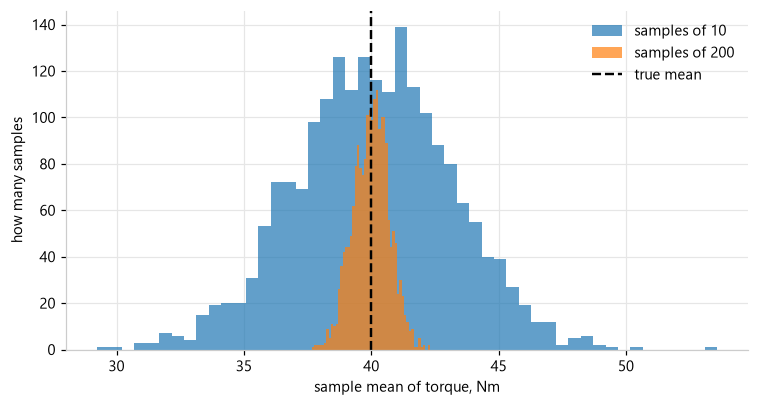

spread with n = 10 : 3.100   sigma / sqrt(10)  = 3.152
spread with n = 200: 0.700   sigma / sqrt(200) = 0.705


In [22]:
rng = np.random.default_rng(42)


def sample_means(size, repeats=2000):
    # the means of `repeats` random samples, each of `size` rows
    means = [rng.choice(population, size, replace=False).mean() for _ in range(repeats)]
    return np.array(means)


means_10 = sample_means(10)
means_200 = sample_means(200)

plt.figure(figsize=(8, 4))
plt.hist(means_10, bins=50, alpha=0.7, label="samples of 10")
plt.hist(means_200, bins=50, alpha=0.7, label="samples of 200")
plt.axvline(true_mean, color="black", ls="--", label="true mean")
plt.xlabel("sample mean of torque, Nm")
plt.ylabel("how many samples")
plt.legend()
plt.show()

sigma = population.std()
se_10 = sigma / np.sqrt(10)
se_200 = sigma / np.sqrt(200)
print(f"spread with n = 10 : {means_10.std():.3f}   sigma / sqrt(10)  = {se_10:.3f}")
print(f"spread with n = 200: {means_200.std():.3f}   sigma / sqrt(200) = {se_200:.3f}")

Twenty times more data, and the spread shrank only about four and a half times. The reason is
a formula. If the $n$ values of a sample are independent draws with standard deviation
$\sigma$, the variance of their mean is

$$\operatorname{Var}(\bar x) = \frac{\sigma^2}{n}, \qquad \text{so the spread of } \bar x \text{ is } \frac{\sigma}{\sqrt n}.$$

The errors of single values partly cancel in the sum, and they cancel only as fast as
$\sqrt n$. The printed $\sigma/\sqrt n$ matches the simulation: 3.15 against 3.10 for 10 rows,
0.705 against 0.700 for 200. (The simulation is a little tighter because we draw without
replacement from a finite population.) Four times more data buys twice the precision, never
four times, which is why "just collect more" soon stops paying.

**Why does the sample variance divide by $n-1$ and not by $n$?**

<details><summary>Answer</summary>

The deviations are measured from $\bar x$, the sample's own mean, and $\bar x$ sits closer to
the sample than the true mean $\mu$ does. The identity
$\sum_i (x_i-\bar x)^2 = \sum_i (x_i-\mu)^2 - n(\bar x-\mu)^2$ makes this exact. Take
expectations: the first sum gives $n\sigma^2$, and $\operatorname{E}(\bar x-\mu)^2 = \sigma^2/n$
from the formula above, so

$$\operatorname{E}\sum_i (x_i-\bar x)^2 = n\sigma^2 - \sigma^2 = (n-1)\,\sigma^2 .$$

Dividing by $n-1$ gives an unbiased estimate of $\sigma^2$. Dividing by $n$ underestimates it by
the factor $(n-1)/n$: 10 % too small for $n = 10$, invisible for 10 000 rows. `np.std` divides
by $n$ (`ddof=0`), pandas `.std()` by $n-1$ (`ddof=1`).

</details>

Torque is the easy case: every row has a value. The failure is the hard one.

In [23]:
p = df["Machine failure"].mean()

for size in [50, 100, 500, 1000]:
    print(f"sample of {size:5d}:  expected failures {size * p:5.1f}   "
          f"chance of getting none: {(1 - p) ** size:.1%}")

sample of    50:  expected failures   1.7   chance of getting none: 17.8%
sample of   100:  expected failures   3.4   chance of getting none: 3.2%
sample of   500:  expected failures  16.9   chance of getting none: 0.0%
sample of  1000:  expected failures  33.9   chance of getting none: 0.0%


Each row fails with probability $p = 0.0339$, so a sample of $n$ rows has no failure at all
with probability $(1-p)^n \approx e^{-np}$. With $n = 50$ the expected count is $np = 1.7$, and
$e^{-1.7}$ is about 0.18: almost one sample in five contains not a single failure. A sample
that is generous for estimating a mean is worthless for the event you were hired to predict.
That is why fault data is split with care instead of being shuffled blindly.

## 5. Mean, median, and where the mean misleads you

The median is the middle value: half the data lie below it, half above. Most of the time it
sits close to the mean. The cases where it does not are the interesting ones.

In [24]:
clean = df["Torque [Nm]"].copy()

broken = clean.copy()
broken.iloc[:20] = 9999          # 20 rows out of 10000: a stuck channel

print(f"{'':8} {'clean':>10} {'20 broken rows':>16}")
print(f"{'mean':8} {clean.mean():>10.2f} {broken.mean():>16.2f}")
print(f"{'median':8} {clean.median():>10.2f} {broken.median():>16.2f}")
print(f"{'std':8} {clean.std():>10.2f} {broken.std():>16.2f}")

              clean   20 broken rows
mean          39.99            59.91
median        40.10            40.10
std            9.97           445.07


Twenty bad rows out of ten thousand moved the mean by 20 Nm and left the median where it was.
The arithmetic is simple: each bad row adds $(9999 - 40)/10\,000 \approx 1$ Nm to the mean, so
one bad value can drag the mean as far as you like. The median only asks which value is in the
middle, and 20 rows at the top end do not change that. On raw sensor data, look at the median
first.

The other trap is averaging over things that are not the same. A machine that idles, ramps up
and cuts is running three different processes, and one mean over all three describes none of
them. `groupby` exists for this.

In [25]:
signals = ["Torque [Nm]", "Rotational speed [rpm]"]
df.groupby("Type")[signals].agg(["mean", "std"]).round(1)

Torque [Nm]        Rotational speed [rpm]        
            mean    std                   mean     std
Type                                                  
H         39.800  9.600              1,538.100 173.100
L         40.000 10.000              1,539.500 180.400
M         40.000 10.000              1,537.600 179.100

Here the three variants turn out to run the same way. That is worth knowing too: on torque and
speed, `Type` alone tells you nothing.

## 6. Plots

Three plots cover most of what you need: the histogram, the boxplot and the scatter plot.

A **histogram** cuts the range into bins and counts the values in each bin. It shows the
shape of the data.

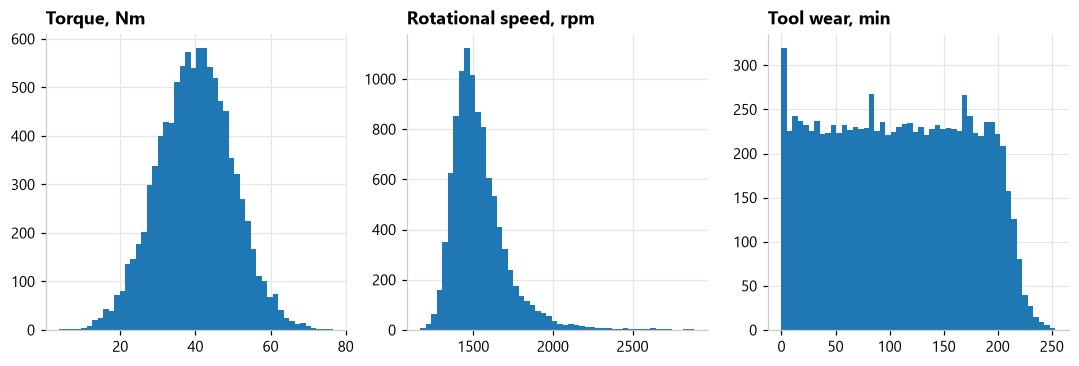

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))

axes[0].hist(df["Torque [Nm]"], bins=50)
axes[0].set_title("Torque, Nm")

axes[1].hist(df["Rotational speed [rpm]"], bins=50)
axes[1].set_title("Rotational speed, rpm")

axes[2].hist(df["Tool wear [min]"], bins=50)
axes[2].set_title("Tool wear, min")

plt.show()

Three different shapes. Torque is a bell: a value wobbling around a set point. Speed is lopsided,
with a tail to the right. Tool wear is flat, because it is a counter. It runs from zero to the
next tool change and starts over, so every value up to the change is about equally common.

A **boxplot** shows the median (the line), the middle half of the data (the box, from the 25th
to the 75th percentile) and the range (the whiskers). The usual rule draws a point separately
when it lies more than 1.5 box widths beyond the box, and calls it an outlier.

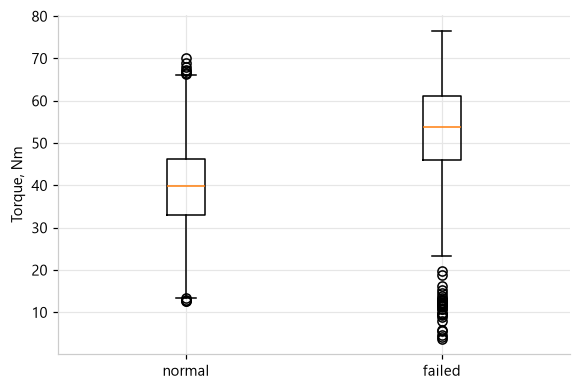

median, normal: 39.9
median, failed: 53.7


In [27]:
normal_rows = df[df["Machine failure"] == 0]["Torque [Nm]"]
failed_rows = df[df["Machine failure"] == 1]["Torque [Nm]"]

plt.figure(figsize=(6, 4))
plt.boxplot([normal_rows, failed_rows])
plt.xticks([1, 2], ["normal", "failed"])
plt.ylabel("Torque, Nm")
plt.show()

print("median, normal:", normal_rows.median())
print("median, failed:", failed_rows.median())

The failed parts sit higher and spread wider, but the boxes still overlap a lot. No threshold
on torque alone will separate the two groups. One sensor rarely answers the question.

A **scatter plot** draws two signals against each other. This is where this data set gives up
its secret.

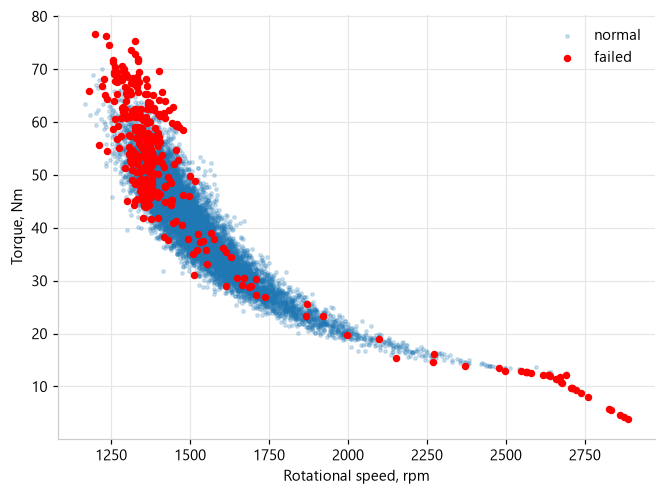

In [28]:
is_fail = df["Machine failure"] == 1

plt.figure(figsize=(7, 5))
plt.scatter(df.loc[~is_fail, "Rotational speed [rpm]"], df.loc[~is_fail, "Torque [Nm]"],
            s=5, alpha=0.2, label="normal")
plt.scatter(df.loc[is_fail, "Rotational speed [rpm]"], df.loc[is_fail, "Torque [Nm]"],
            s=15, color="red", label="failed")

plt.xlabel("Rotational speed, rpm")
plt.ylabel("Torque, Nm")
plt.legend()
plt.show()

The red points are not scattered at random. Many of them sit in two bands, one along the
top-left edge of the cloud and one along the bottom-right. Neither histogram showed that.

The bands follow curves of constant mechanical power. Power is torque times angular speed, and
an angular speed of $n$ revolutions per minute is $2\pi n / 60$ radians per second:

$$P = M \cdot \frac{2\pi n}{60} \quad [\text{W}], \qquad M \text{ in N·m}, \; n \text{ in rpm}.$$

For a fixed $P$ the torque is $M = 60P/(2\pi n)$, a hyperbola in the (speed, torque) plane. The
machine breaks when the power is too low or too high, so the failures line up along two of
these hyperbolas. Compute the power and check.

In [29]:
df["power"] = df["Torque [Nm]"] * df["Rotational speed [rpm]"] * 2 * np.pi / 60   # W

outside = (df["power"] < 3500) | (df["power"] > 9000)

print("rows outside 3500..9000 W:", outside.sum())
print("rows where PWF fired     :", df["PWF"].sum())
print("the same rows            :", (outside.astype(int) == df["PWF"]).all())

rows outside 3500..9000 W: 95
rows where PWF fired     : 95
the same rows            : True


The same rows, all 95 of them. One new column, built from two old ones and a formula from a
physics textbook, reproduces a whole failure mode without any model.

This is feature engineering, and it is why this course keeps asking what the machine is
physically doing. Speed and torque on their own did not separate the power failures. Their
product does.

## 7. Noise

Every real signal arrives with something added on top. The lecture calls it noise and says you
filter it before you feed a model. There are several kinds, and they need different treatment:

- **random noise**: small random errors from the sensor and the analogue-to-digital converter.
  Averaging reduces it;
- **periodic interference**: something that oscillates at a fixed frequency, such as the 50 Hz
  mains, an unbalanced rotor or gear teeth. It looks like noise but is not random at all;
- **drift**: a slow crawl in one direction, from a sensor that ages or warms up;
- **spikes**: rare large jumps, from switching or a lost packet.

To see what each one does we need a signal whose true value we know. Take a motor drive that
holds a steady set point of 35.9 Hz and is polled about twice a second. The truth is a flat
line, a hundred samples long. Now we spoil it on purpose.

In [30]:
F_SET = 35.9          # Hz, the drive's set point: this is the truth
TS = 0.425            # s between samples
F_COS = 0.235         # Hz, frequency of the periodic interference: one cycle per 4.25 s
A_COS = 1.5           # Hz, its amplitude
ALARM = 37.0          # Hz, a fixed alarm limit

clean_signal = np.full(100, F_SET)
t = np.arange(100) * TS

print("length:", len(clean_signal), "samples")
print("values:", np.unique(clean_signal), "Hz")
print("span  :", round(t[-1], 1), "s")

length: 100 samples
values: [35.9] Hz
span  : 42.1 s


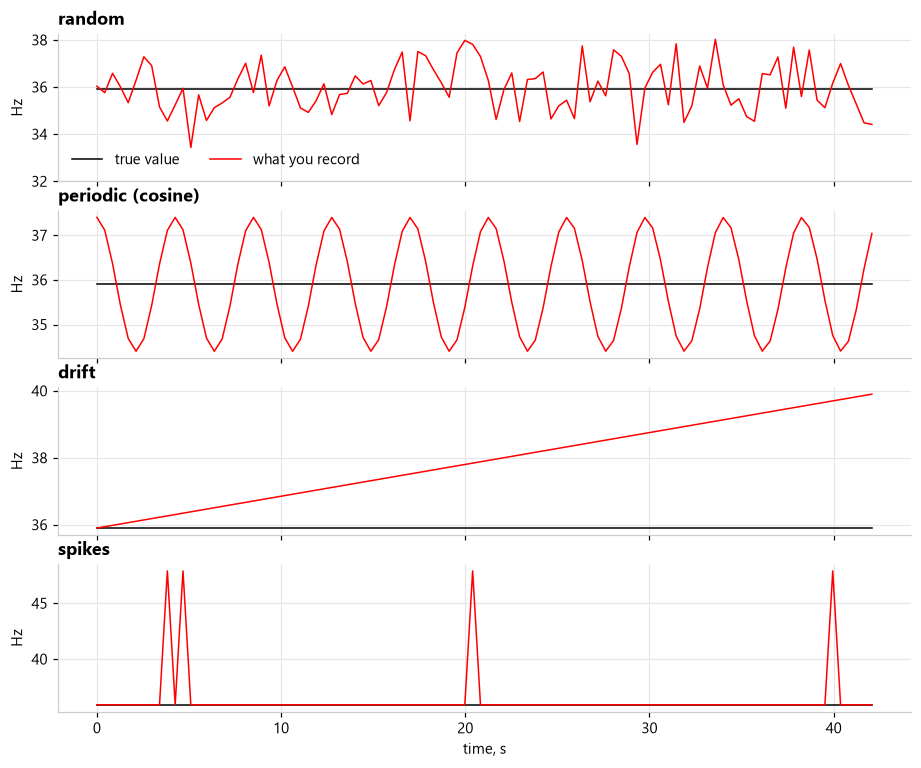

In [31]:
rng = np.random.default_rng(0)

random_noise = rng.normal(0, A_COS / np.sqrt(2), 100)     # random, same std as the cosine
cosine_noise = A_COS * np.cos(2 * np.pi * F_COS * t)      # periodic
drift = np.linspace(0, 4, 100)                            # slow crawl
spikes = np.where(rng.random(100) < 0.03, 12, 0)          # rare jumps

noises = [("random", random_noise),
          ("periodic (cosine)", cosine_noise),
          ("drift", drift),
          ("spikes", spikes)]

fig, axes = plt.subplots(4, 1, figsize=(10, 8), sharex=True)

for ax, (name, noise) in zip(axes, noises):
    ax.plot(t, clean_signal, color="black", lw=1, label="true value")
    ax.plot(t, clean_signal + noise, color="red", lw=1, label="what you record")
    ax.set(ylabel="Hz")
    ax.set_title(name, loc="left")

axes[0].set_ylim(bottom=32)                # room for the legend
axes[0].legend(loc="lower left", ncol=2)
axes[-1].set(xlabel="time, s")
plt.show()

### The cosine case

The periodic disturbance is the interesting one, because it hides from the statistics you have
just learned.

Over a whole period $\cos^2$ averages to $\tfrac12$, so a cosine of amplitude $A$ has mean 0
and standard deviation $A/\sqrt{2}$. Take random noise with exactly that standard deviation and
compare the two.

In [32]:
sigma_cos = A_COS / np.sqrt(2)

n_pts = 20000
cosine = A_COS * np.cos(np.arange(n_pts))
random_ = np.random.default_rng(1).normal(0, sigma_cos, n_pts)

print(f"{'':10} {'mean':>10} {'std':>10}")
print(f"{'cosine':10} {cosine.mean():>10.4f} {cosine.std():>10.4f}")
print(f"{'random':10} {random_.mean():>10.4f} {random_.std():>10.4f}")

                 mean        std
cosine         0.0000     1.0607
random        -0.0120     1.0544


Mean zero and standard deviation 1.06 in both cases. Every summary number that `describe()`
prints comes out equal to two decimals.

**Question.** Do the two signals look the same? Guess the shape of each histogram before you
run the cell.

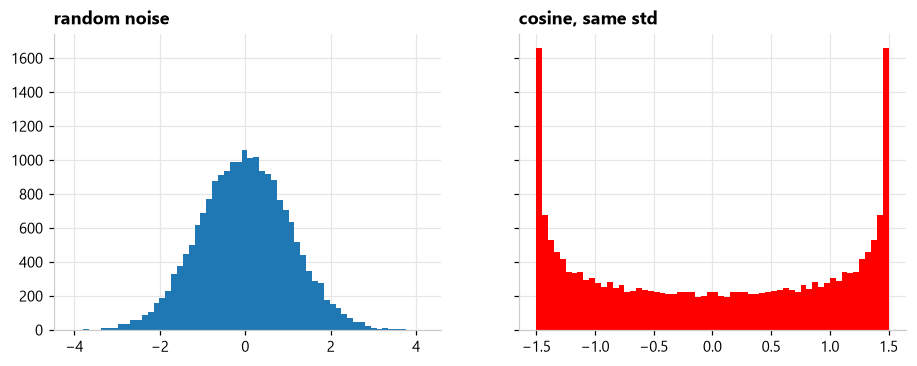

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)

axes[0].hist(random_, bins=60)
axes[0].set_title("random noise")

axes[1].hist(cosine, bins=60, color="red")
axes[1].set_title("cosine, same std")

plt.show()

**Answer.** A bell against a bathtub. A cosine moves slowly near its peaks and fast through
zero, like a pendulum that stops at the ends and flies through the bottom. So it spends most of
its time close to $\pm A$ and little in the middle. The exact shape is the arcsine density
$f(x) = 1 / \left(\pi\sqrt{A^2 - x^2}\right)$ on $(-A, A)$, which grows without bound at the
two ends. Two signals with identical summary statistics behave in completely different ways.

Mean and standard deviation cannot tell interference from noise. A histogram tells them apart at
a glance.

The boxplot has the same blind spot.

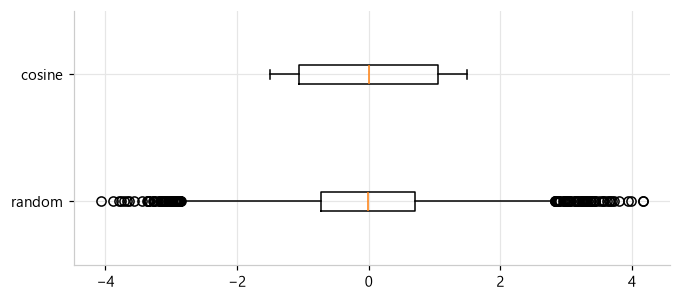

random   box width 1.423   outliers flagged: 0.65 %
cosine   box width 2.118   outliers flagged: 0.00 %


In [34]:
plt.figure(figsize=(7, 3))
plt.boxplot([random_, cosine], vert=False)
plt.yticks([1, 2], ["random", "cosine"])
plt.show()

for name, x in [("random", random_), ("cosine", cosine)]:
    q1, q3 = np.percentile(x, [25, 75])
    box = q3 - q1
    flagged = ((x < q1 - 1.5 * box) | (x > q3 + 1.5 * box)).mean()
    print(f"{name:8} box width {box:.3f}   outliers flagged: {100 * flagged:.2f} %")

Zero. A pure cosine never produces a boxplot outlier, however large its amplitude. Its quartiles
are $\pm A/\sqrt2$, so the box is $\sqrt2\,A$ wide (2.118 here, for $A = 1.5$), and the upper
fence sits at $A/\sqrt2 + 1.5\sqrt2\,A \approx 2.8A$. The signal never goes beyond $A$, so it
never reaches the fence. The lecture calls the boxplot a tool for catching sensor faults, and
for periodic interference it is blind.

### Removing it

Random noise can only be averaged down. Periodic interference can be removed exactly if you
know its period: average over a window of exactly one period and the cosine cancels itself.
The $w$ samples of one period are $w$ equally spaced points on a circle, and such points add up
to zero.

One cycle here lasts $1/F_{\cos} = 4.25$ s, which is 10 samples.

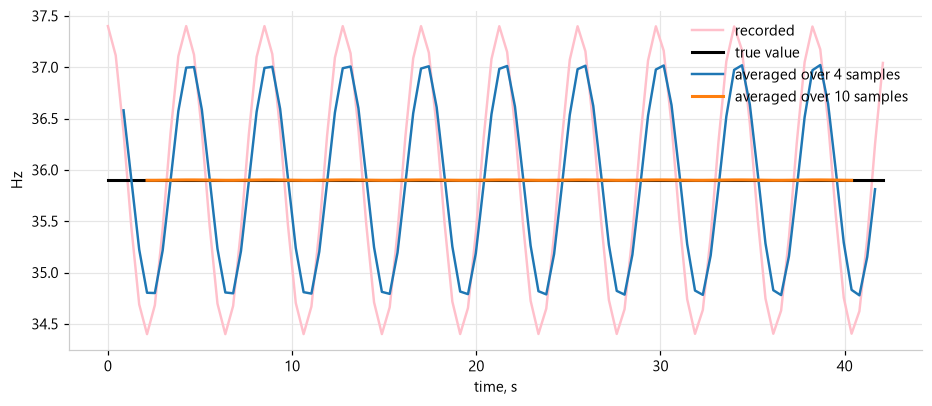

In [35]:
def moving_average(x, window):
    # centred running mean; NaN at the two ends where the window does not fit
    return pd.Series(x).rolling(window, center=True).mean().to_numpy()


noisy = clean_signal + cosine_noise

plt.figure(figsize=(10, 4))
plt.plot(t, noisy, color="pink", label="recorded")
plt.plot(t, clean_signal, color="black", lw=2, label="true value")
plt.plot(t, moving_average(noisy, 4), label="averaged over 4 samples")
plt.plot(t, moving_average(noisy, 10), lw=2, label="averaged over 10 samples")
plt.xlabel("time, s")
plt.ylabel("Hz")
plt.legend()
plt.show()

The 10-sample average lands on the true value. The 4-sample one barely helps. The window is not
a matter of taste: it comes from the period of the thing you want gone.

And the cost of not doing it, in the terms a plant cares about: how often a fixed alarm limit
fires.

In [36]:
variants = [("true signal",        clean_signal),
            ("+ random noise",     clean_signal + random_noise),
            ("+ cosine",           noisy),
            ("+ cosine, averaged", moving_average(noisy, 10))]

for name, signal in variants:
    fired = int(np.nansum(signal > ALARM))
    print(f"{name:20} mean {np.nanmean(signal):.2f}   alarms: {fired} of 100")

true signal          mean 35.90   alarms: 0 of 100
+ random noise       mean 35.99   alarms: 18 of 100
+ cosine             mean 35.90   alarms: 30 of 100
+ cosine, averaged   mean 35.90   alarms: 0 of 100


The drive ran at a steady 35.9 Hz the whole time and never came near 37. The mean barely moves
in any row of that table. Still, the alarm went off 30 times on the cosine, and one moving
average with the right window brought it back to zero.

Thirty false alarms in under a minute are how an operator learns to ignore the alarm.

## 8. PyTorch, briefly

We need PyTorch from Practice 4 on. Two ideas today.

A **tensor** is a NumPy array that also remembers what was computed from it.

In [37]:
import torch

x = torch.tensor([1.0, 2.0, 3.0])
y = torch.tensor([4.0, 5.0, 6.0])

print(x + y)
print(x * y)
print(torch.from_numpy(np.array([1.0, 2.0])))     # numpy -> torch
print(x.numpy())                                  # torch -> numpy

tensor([5., 7., 9.])
tensor([ 4., 10., 18.])
tensor([1., 2.], dtype=torch.float64)
[1. 2. 3.]


Because it remembers, PyTorch can differentiate what you wrote. This is the mechanism behind
training a network: write the formula, ask for the derivative, take a step in the direction
that lowers the error.

In [38]:
x = torch.tensor(2.0, requires_grad=True)

y = 3 * x ** 2 + 5 * x - 1
y.backward()

print("y at x = 2    :", y.item())
print("dy/dx by torch:", x.grad.item())
print("dy/dx by hand :", 6 * 2 + 5)

y at x = 2    : 21.0
dy/dx by torch: 17.0
dy/dx by hand : 17


By hand, $\frac{d}{dx}(3x^2 + 5x - 1) = 6x + 5$, which is 17 at $x = 2$. From Practice 4 on, the
same `backward()` runs over a network with hundreds of parameters instead of one number.

Those networks train faster on a graphics card. PyTorch works out whether it can see one, and
every notebook of the course that trains a network starts with the line below and puts the
model and the data on `DEVICE`. Run it now: if it prints `cpu` on a laptop with an NVIDIA card,
you installed the CPU build of PyTorch. The GPU build for your CUDA version is listed at
<https://pytorch.org/get-started/locally/>. The CPU is enough for everything in the course,
only slower.

In [39]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

card = ""
if DEVICE.type == "cuda":
    card = f"({torch.cuda.get_device_name(0)})"
print("device:", DEVICE, card)

device: cuda (NVIDIA GeForce RTX 5080 Laptop GPU)


## Further reading

- Robust estimates. The median and the median absolute deviation,
  $\text{MAD} = \operatorname{median}_i |x_i - \operatorname{median}(x)|$, barely move when a
  few readings are wrong, which is what section 5 showed for the median. Multiplied by 1.4826,
  the MAD estimates $\sigma$ of normal data, so a limit such as
  $\operatorname{median} \pm 3 \cdot 1.4826\,\text{MAD}$ flags outliers in raw sensor data
  without being dragged by them. The classic book is P. J. Huber, *Robust Statistics*, Wiley,
  1981.

## 9. Tasks

Do these in this notebook and keep the code. Nothing is graded, but the same steps come back in
Practice 1 next week.

**T1.** Print the mean, median and standard deviation of `Air temperature [K]` and
`Process temperature [K]`. Which of the two varies more? Does that make physical sense?

**T2.** Make a new column `temp_diff`, the process temperature minus the air temperature, and
plot its histogram. What is its average, roughly, and why is it not zero?

**T3.** Use `groupby` to compare the failure rate of the three variants L, M and H. Does the
variant matter? Hint: the mean of a 0/1 column is a rate.

**T4.** Repeat the samples-of-50 experiment from section 4 with `Tool wear [min]` instead of
torque. Is the spread of the sample means larger or smaller? Explain it with the histograms of
section 6.

**T5.** Repeat the cosine experiment of section 7 with amplitude 0.5 instead of 1.5. How many
alarms does the 37.0 Hz limit raise now? What does that say about when interference matters?

**T6** (if you have time). We averaged over 10 samples because one cycle is 10 samples long. Try
windows of 5, 9, 10, 11 and 20 and print how far each result ends up from the true 35.9 Hz.
Which windows work, and can you say why?

Worked answers to all six are in the companion notebook, `inclass_work_1_solutions.ipynb`. Open
it after a real attempt at the tasks. The twenty minutes of being stuck are the part that
teaches you something.